In [6]:
"""
File: compare_tng_to_spam.py
Author: Matthew Ogden
Email: ogdenm12@gmail.com
Github: mbogden
Created: 2024-Nov-12

Description: During the TNG to SPAM unit conversion process, I discovered
    that the default SPAM hyperparameters were not optimal.   But in order to 
    fine-tune them, I needed a metric to quantify the similarity between TNG and SPAM.
    Thus, this module creates a few methods for comparing the two simulations.

References: 
- Sections of this code were written with the assistance of ChatGPT made by OpenAI.
- TNG50 Simulation Data
    - Nelson, D. et al. (2015). The Illustris Simulation: Public Data Release. Astronomy and Computing, 13, 12–37. https://doi.org/10.1016/j.ascom.2015.09.003
    - Nelson, D. et al. (2019). First results from the TNG50 simulation: Galactic outflows driven by supernovae and black hole feedback. Monthly Notices of the Royal Astronomical Society, 490(3), 3234–3261. https://doi.org/10.1093/mnras/stz2306
    - Pillepich, A. et al. (2019). First results from the TNG50 simulation: The evolution of stellar and gaseous discs across cosmic time. Monthly Notices of the Royal Astronomical Society, 490(3), 3196–3233. https://doi.org/10.1093/mnras/stz2338

"""
# ================================ IMPORTS ================================ #
import hashlib, os, sys, logging, time
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from mpi4py import MPI
from copy import deepcopy
import glob

# Add main project directory to import project modules
try:
    SCRIPT_DIRECTORY = os.path.dirname(os.path.realpath(__file__))
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    sys.path.append(PROJECT_DIRECTORY)

except:
    # Assume we are running from the script directory
    SCRIPT_DIRECTORY = os.getcwd()
    PROJECT_DIRECTORY = os.path.dirname(SCRIPT_DIRECTORY)
    
    # Also assume you might be in galStuff directory
    work_dir = os.getcwd()
    if 'galStuff' == work_dir.split('/')[-1]:
        PROJECT_DIRECTORY =  work_dir + '/galaxyJSPAM'
        sys.path.append(PROJECT_DIRECTORY)

# Import project modules
import IllustrisTNG.tng_functions as tf
import IllustrisTNG.convert_tng_to_spam as cts
import utilities.parallel_queue_manager as qm
# import Optimization_Methods.optimization_manager as om
import Simulator.new_simulator as sim
import utilities.general_utility as gu

# ================================ GLOBALS ================================ #
script_args, logger = gu.initialize_environment( module_name='spam_tuner' )
buildEnv = False  # For testing and development purposes only

# Set NumPy print options to reduce the precision to 3 decimal places
logger.debug("Imports Done")

In [7]:
# Development Cell:  This should only be present in the development Jupyter Notebook version of this script
buildEnv = True

from importlib import reload

# Warn user if NOT in jupyter notebook, require a yes/no response to continue or not
if "ipykernel" not in sys.modules:
    msg = "Development Environment Detected.  Do you want to continue?..."

    # Get user input
    while True:
        response = input(f"{msg} (y/n): ").lower()
        if response in ['y', 'yes']:
            break
        elif response in ['n', 'no']:
            print("Exiting...")
            sys.exit()
        else:
            print("Invalid input. Please enter 'y' or 'n'.")



---
---
# TNG Sample Targets
Let's load a few targets and example orbits that we'll want to score.  

[2026-01-09 13:16:26,473 - INFO - new_simulator.spam_orbit]: Running SPAM Simulation - Orbit Run
[2026-01-09 13:16:26,476 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 
[2026-01-09 13:16:26,625 - INFO - new_simulator.spam_orbit]: Running SPAM Simulation - Orbit Run
[2026-01-09 13:16:26,627 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 
[2026-01-09 13:16:26,851 - INFO - new_simulator.spam_orbit]: Running SPAM Simulation - Orbit Run
[2026-01-09 13:16:26,853 - INFO - new_simulator.set_spam_parameters]: Setting SPAM Parameters: 


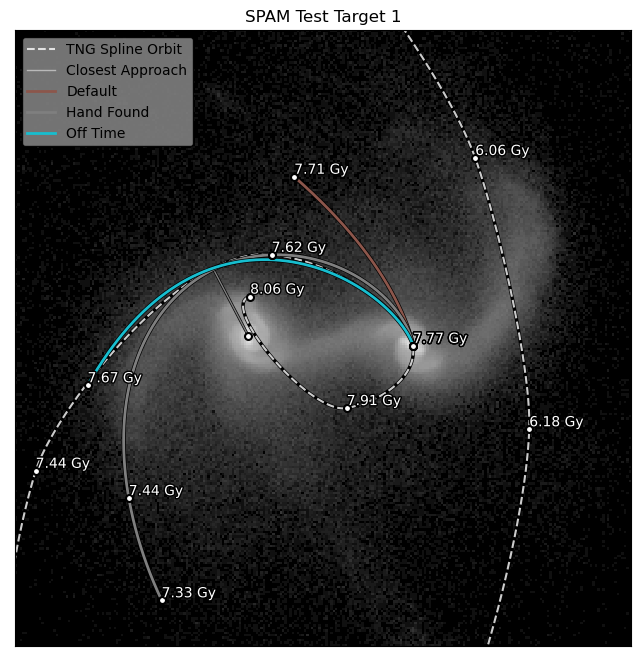

In [8]:
if buildEnv and True:

    # Set logger level
    logger.setLevel(logging.INFO)
    
    # Target Unique IDs
    p1 = 62000000190717 
    p2 = 75000000121160 

    spam_test = {
        'Default':{ 'param':{}},
        'Hand Found':{ 'param': { 'm_halo': 6.4, 'lnl': 0.005, 'r_scale': 19.5 } },
        'Off Time': {'param': { 'm_halo': 12, 'lnl': 0.045, 'r_scale':10, } }
    }

    # Load TNG Target from convert_tng_to_spam
    target_1 = cts.TNG_Target_Class( p1, log_level = logging.WARNING )
    target_1._gen_spam_collision_parameters( radius_scale=7.5 )  # Give a bigger radius.
    data_1 = deepcopy(spam_test)

    
    # target_2 = cts.TNG_Target_Class( p2, log_level = logging.WARNING )
    # target_2.plot_target()
    # data_2 = deepcopy(spam_test)

    # Create plot lists
    plot_list_1 = []
    anno_list_1 = []

    plot_list_2 = []
    anno_list_2 = []

    for key, value in spam_test.items():

        # Generate orbit for target 1
        data_1[key]['orbit'] = target_1.run_spam_orbit( data_1[key]['param'] )
        data_1[key]['anno'] = target_1.gen_spam_orbit_annotations( data_1[key]['orbit'] )

        plot_list_1.append( (data_1[key]['orbit'], key ) )
        anno_list_1.extend( data_1[key]['anno'] )

        # # Target 2
        # data_2[key]['orbit'] = target_2.run_spam_orbit( data_2[key]['param'] )
        # data_2[key]['anno'] = target_2.gen_spam_orbit_annotations( data_2[key]['orbit'] )
        # plot_list_2.append( (data_2[key]['orbit'], key ) )
        # anno_list_2.extend( data_2[key]['anno'] )


    target_1.plot_target( 
        append_plots = plot_list_1,
        append_annotations = anno_list_1,
        plot_title = 'SPAM Test Target 1',
    )

    # target_2.plot_target(
    #     append_plots = plot_list_2,
    #     append_annotations = anno_list_2,
    #     plot_title = 'SPAM Test Target 2',
    # )
    # Compare the two targets

        

---
---
# Orbit Similarity Function
## Inital Problems
While trying a few simple fitness function's for comparing the TNG and SPAM simulation, I came across 2 primary issues:

1) The SPAM simulation ends early if galaxies are not likely to merge.  This is to preserve computational resources for other SPAM runs. 
2) The SPAM and TNG starting parameters are identical (since they use the same starting parameters).  Thus SPAM runs that end early, have orbit paths that are very close to TNG. 

## Solution
Accordinging to literature, the tidal features of merging galaxies are highly influenced by the moment of closest approach (when the two galaxies are closest), because that is when tidal forces are highest.  Therefore, I decided to implement two aspects to the orbit similarity fitness function that keeps this in mind. 

2) **Fixed Time Frame** - Calculate a fixed time frame centered around the moment of closest approach (MOCA) in TNG Spline.  If the SPAM orbit ends early (fails to simulate far enough back in time) it will be punished.
1) **Weighted Fitness Function** - Give more importance to the weight function centered on the moment of closest approach.  Have weights drop the further you are from this point.   


NOTE: A cautious about wording orbit times within SPAM simulation.  The SPAM simulation takes collision parameters for the **current** moment (what we observe) and simulates an orbit of the galaxies *backwards* in time.   Thus, the start of the orbit simuation is **fixed** at the final position and time, and integrates backwards to earlier times/positions of the orbit.  Making the end of the simulation the **starting** time.  I make this note it has caused some confusion while coding and explaining to others. 

---
---



### Weighted Fitness Function

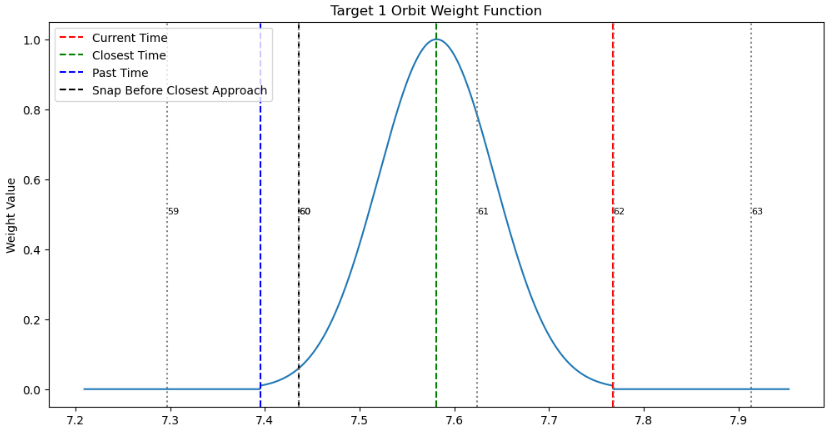

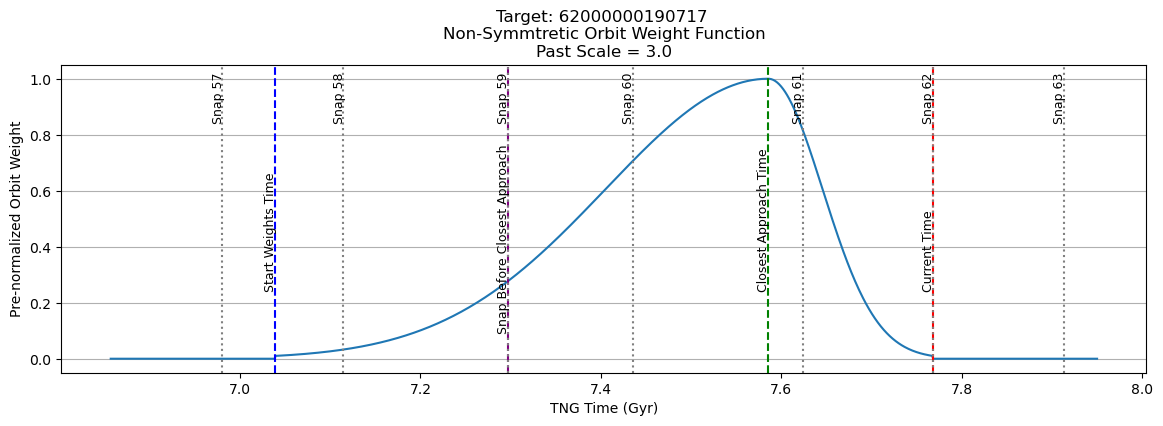

<Figure size 640x480 with 0 Axes>

In [9]:
class SPAM_TNG_Tuner( cts.TNG_Target_Class ):
    """
    Developement Class to compare TNG and SPAM orbits.  
    Will eventually be used to tune SPAM parameters to match TNG orbits.
    Currently buildin
    g and developing the class.

    """

    def gen_moca_weight_func( self, boundary_value = 0.01, scale_past = 1.0 ):
        """
        Generate weight function for a gaussian function centered on the moment of closest approach (moca).
        Meant to weigh a fitness function comparing TNG and SPAM orbits.
        The weighting function will be zero outside of the inbound and current snapshot of the orbit.

        path: dict - Accumlated orbit path information for a particular TNG target
        weight_boundary: float (0,1) - The value of the weighting function at current time.
        scale_past: float (Defualt 1.0) - Scale the weighting function for times before the closest approach.
        """

        self.logger.info("Generating MOCA Weight Function")

        # Build dictionary to contain variables and weight function
        self.moca_weight_var = {}  # moca weight function

        # Weight function variables
        self.moca_weight_var['delta_time'] = self.moca['current']['time_su'] - self.moca['closest']['time_su']
        self.moca_weight_var['start_time'] = self.moca['closest']['time_su'] - self.moca_weight_var['delta_time'] * scale_past

        start_time = self.moca_weight_var['start_time']
        current_time = self.moca['current']['time_su']
        closest_time = self.moca['closest']['time_su']
        gaussian_weight_after = - ( self.moca_weight_var['delta_time']**2 / (2 * np.log( boundary_value ) ) )
        gaussian_weight_before = - ( (scale_past*self.moca_weight_var['delta_time'])**2 / (2 * np.log( boundary_value ) ) )

        # The actual weight function
        def weight_func( time ):
            """
            Generate the weight for a given time
            """

            # If a list or array, recursively apply the function to each element
            if isinstance(time, list) or isinstance(time, np.ndarray):
                return np.array([ weight_func( t ) for t in time ])

            # If outside of weight range, return 0
            if time < start_time:    return 0
            elif time > current_time:    return 0

            # between closest and current time
            elif time > closest_time:    
                return np.exp( -( (time - closest_time)**2 / (2*gaussian_weight_after) ) )

            # else between start and closest time
            else:    
                return np.exp( -( (time - closest_time)**2 / (2*gaussian_weight_before) ) )
        
        self.moca_weight_func = weight_func

        self.logger.info("MOCA Weight Function Generated")
        self.logger.debug(f"Weight Function Variables: {self.moca_weight_var}")

        return weight_func

# setattr( SPAM_TNG_Tuner, 'gen_moca_weight_func', gen_moca_weight_func )

    def plot_moca_weight_function( self, title = "Orbit Weight Function",  scale_past=1.0 ):
        """
        Plot the weight function for the given path
        """

        # Generate test times
        plot_start = self.moca['inbound']['time_su']-self.moca_weight_var['delta_time'] * scale_past
        plot_end = self.moca['current']['time_su']+self.moca_weight_var['delta_time']
        plot_times_su = np.linspace( plot_start, plot_end, 1000 )
        plot_weights = self.moca_weight_func( plot_times_su )
        plot_times_tng = self.convert_time_spam_to_tng( plot_times_su )

        plt.clf()
        plt.plot( plot_times_tng, plot_weights )

        plt.title(title)
        plt.xlabel("TNG Time (Gyr)")
        plt.ylabel("Pre-normalized Orbit Weight")

        #
        t_off = -0.012
        t_font = 9

        # Add vertical dash lines for current, past, and closest times
        c_val = self.convert_time_spam_to_tng( self.moca['current']['time_su'])
        plt.axvline( c_val, color='r', linestyle='--', label='Current Time' )
        plt.text( c_val+t_off, 0.25, f"Current Time", rotation=90, fontsize=t_font, )

        t_val = self.convert_time_spam_to_tng( self.moca['closest']['time_su'] )
        plt.axvline( t_val, color='g', linestyle='--', label='Closest Time' )
        plt.text( t_val+t_off, 0.25, f"Closest Approach Time", rotation=90, fontsize=t_font, )

        p_val = self.convert_time_spam_to_tng( self.moca_weight_var['start_time'] )
        plt.axvline( p_val, color='b', linestyle='--', label='Weight Start Time' )
        plt.text( p_val+t_off, 0.25, f"Start Weights Time", rotation=90, fontsize=t_font, )

        # Show time of snap before closest approach
        sb_val = self.convert_time_spam_to_tng( self.inbound_state['time_su'] )
        plt.axvline( sb_val, color='purple', linestyle='--', label='Snap Before Closest Approach' )
        plt.text( sb_val+t_off, 0.1, f"Snap Before Closest Approach", rotation=90, fontsize=t_font, )
        
        # Add snap times and lines to plot
        snap_list = []

        for i in range( len( self.state_history['snap'].values ) ):

            # If between plot time, add to plot
            if self.state_history['time_su'][i] > plot_start and self.state_history['time_su'][i] < plot_end:

                # snap_list.append(tng_target['snaps'][i] )
                s_val = self.convert_time_spam_to_tng( self.state_history['time_su'][i] )
                plt.axvline( s_val, color='grey', linestyle=':', )
                plt.text( s_val+t_off, 0.85, f"Snap {self.state_history['snap'][i]}", rotation=90, fontsize=t_font )

        # Make plot bigger
        plt.gcf().set_size_inches(14, 4)

        # Add only horizontal gridlines
        plt.grid(axis='y')

        # # Legend
        # plt.legend()
        plt.show()
        plt.clf()
        
    # end function
    
if buildEnv:

    test_target = SPAM_TNG_Tuner( p1, log_level = logging.WARNING )
    wf1 = test_target.gen_moca_weight_func( scale_past=3.0 )
    test_target.plot_moca_weight_function( scale_past=3.0, title=f"Target: {test_target.target_id} \nNon-Symmtretic Orbit Weight Function\nPast Scale = 3.0" )


## Weighted Orbit Similarity Fitness Function

Here is the basis for this function.

1) Sets a fixed time frame to score, based on spline of TNG orbit centered around the moment of closest approach.  
1) It takes the time steps from the SPAM orbit.  If shorter than fixed time frame, it extends to the timesteps to the full time.
1) Those timesteps are used to generate weight values and positions from the TNG orbit spline.  
1) Iterates over each time step, calculating the distance squared between orbit positions.  
1) If SPAM does not go fully back in time, the function iterates over the remaining TNG orbit and computes the difference between it and the starting SPAM position.
1) Weights are applied to the errors, and normalized so it's the average weighted error.  

1) TODO: Consider making area under the curve the same, before and after.  But, make it so the inbound stretches back further.  


___
## Orbit Similarity Score: Weighted Avg Error Sq by Time and Position

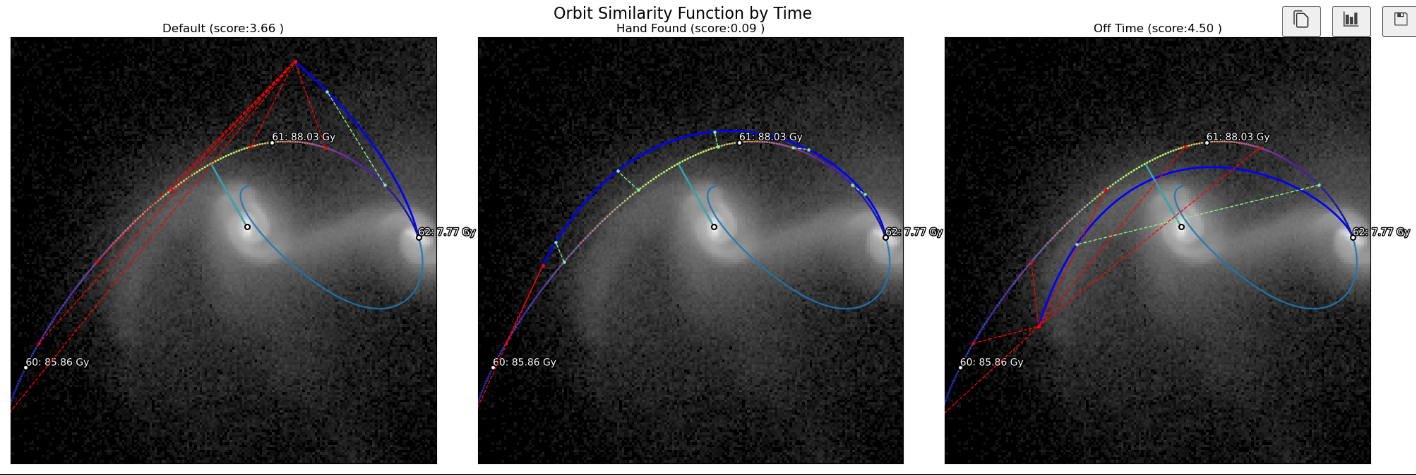

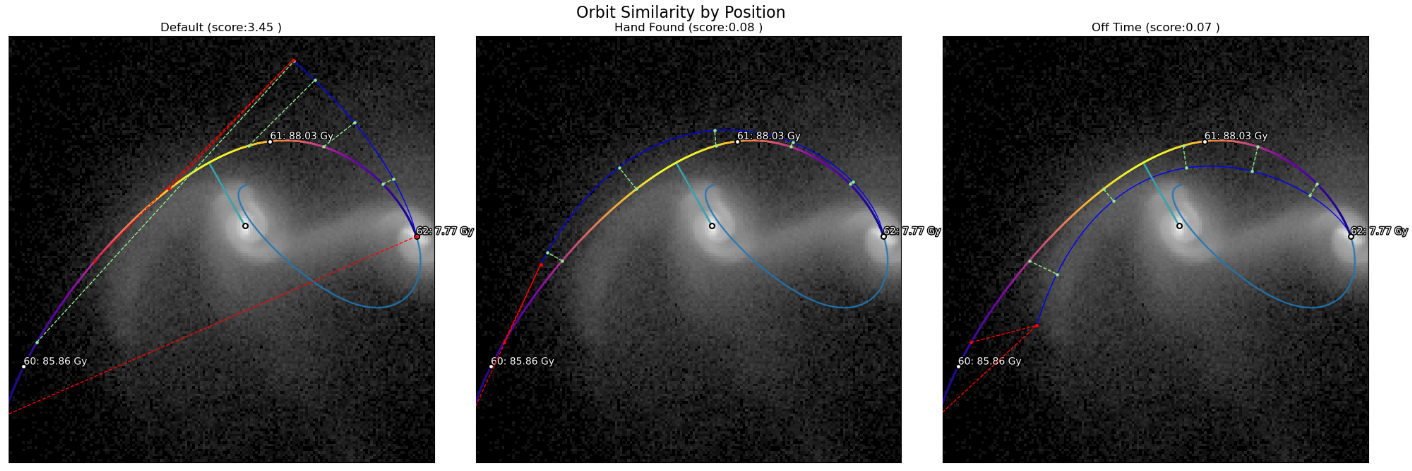

While the orbit similarity by time is ideally the best scoring function, I also thought it'd be good to have an intermediate score to "encourage" future optimizers to converge upon the orbital path earlier. 

In [10]:
def weighted_avg_error_sq_over_time( self, spam_orbit, weight_func = None, ):

    self.logger.info("Weighted Average Error Squared Over Time")

    # Get info from SPAM orbit
    n_spam = len(spam_orbit)  # length of spam run
    spam_times = spam_orbit[:,-1]  # Times in spam run

    self.logger.debug("SPAM Orbit: %s", spam_orbit.shape)
    self.logger.debug( f"SPAM Time: {spam_times[0]:.2f} - {spam_times[-1]:.2f} Gyr")

    # If spam run ends before the inbound time, add more time steps
    if spam_times[0] > self.moca['inbound']['time_su']:
        self.logger.debug("SPAM run ended before reaching inbound time")

        # Get steps needed to fill the gap between inbound time and spam start
        spam_dt = abs((spam_times[-1] - spam_times[0]) / (n_spam - 1))
        n_more = int( np.ceil( (spam_times[0] - self.moca['inbound']['time_su']) / spam_dt ) )
        self.logger.debug( f"Adding {n_more} more time steps to SPAM run")
        self.logger.debug( f"SPAM Times: {spam_times.shape}")
        self.logger.debug( f"{spam_times[:3]} - {spam_times[-3:]}")

        # Create new time array that stretches the gap
        new_times = np.linspace( self.moca['inbound']['time_su'], spam_times[0], n_more )        
        self.logger.debug( f"New Times: {new_times.shape}")
        self.logger.debug( f"{new_times[:3]} - {new_times[-3:]}")
        
        # Combine SPAM and new times
        times = np.concatenate( (new_times, spam_times) )

    # Else use the spam run times
    else:
        n_more = 0
        times = spam_times

    # Log time steps
    self.logger.debug( f"Comparing Times: {times.shape}")
    self.logger.debug( f"{times[:3]} - {times[-3:]}")

    # Create presumed tng_orbit using spline and times
    n = len(times)  # length of times array
    tng_spline_orbit = self.gen_orbit_from_spline( times ) # TNG orbit from spline
    self.logger.debug( f"TNG Spline Orbit: {tng_spline_orbit.shape}")
    
    # Create weights from tng_orbit
    if weight_func is None:
        weights = self.moca_weight_func( times )
    else:
        weights = weight_func( times )
        
    self.logger.debug( f"Weights: {weights.shape}")

    # Loop through orbits and compute errors
    errors = np.zeros(n)
    for i in range(n):

        # If time is less than SPAM start, compare to spam's starting point
        if i < n_more:
            e = np.linalg.norm(spam_orbit[0,0:3] - tng_spline_orbit[i,0:3]) ** 2
        
        # Else compare orbits at same time step
        else:
            spam_idx = i - n_more
            e = np.linalg.norm(spam_orbit[spam_idx,0:3] - tng_spline_orbit[i,0:3]) ** 2

        errors[i] = e

    self.logger.debug( f"Errors: {errors.shape}")

    # Calcule normalization factor for normalized weighted error
    total_weight = np.sum(weights)
    E = np.sum(weights * errors)
    E_normalized = E / total_weight

    self.logger.debug( f"Total Weight: {total_weight}")
    self.logger.debug( f"Total Error: {E}")
    self.logger.debug( f"Weighted Error: {E_normalized}")

    return E_normalized
setattr( SPAM_TNG_Tuner, 'weighted_avg_error_sq_over_time', weighted_avg_error_sq_over_time )

if buildEnv:

    test_target = SPAM_TNG_Tuner(  p1, log_level= logging.WARNING )
    wf_1 = test_target.gen_moca_weight_func(  )
    wf_2 = test_target.gen_moca_weight_func( boundary_value = 0.1, scale_past = 0.5 )

    test_target.set_log_level( logging.INFO )

    for key, value in data_1.items():
        score1 = test_target.weighted_avg_error_sq_over_time( data_1[key]['orbit'], weight_func = wf_1 )
        score2 = test_target.weighted_avg_error_sq_over_time( data_1[key]['orbit'], weight_func = wf_2 )
        print( f"{key}: Weight Func Default - {score1:.5f}" )
        print( f"{key}: Weight Func Test    - {score2:.5f}" )
    
    # test_target_2 = SPAM_TNG_Tuner( p2, log_level= logging.WARNING )
    # test_target_2.gen_moca_weight_func( )

    # for key, value in data_2.items():
    #     score1 = test_target_2.weighted_avg_error_sq_over_time( data_2[key]['orbit'] )
    #     print( f"{key}: Weight Func Default - {score1:.5f}" )

[2026-01-09 13:16:31,485 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time
[2026-01-09 13:16:31,528 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time
[2026-01-09 13:16:31,569 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time
[2026-01-09 13:16:31,616 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time
[2026-01-09 13:16:31,659 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time
[2026-01-09 13:16:31,702 - INFO - 2851012578.weighted_avg_error_sq_over_time]: Weighted Average Error Squared Over Time


Default: Weight Func Default - 3.76550
Default: Weight Func Test    - 2.30524
Hand Found: Weight Func Default - 0.09303
Hand Found: Weight Func Test    - 0.03830
Off Time: Weight Func Default - 3.63985
Off Time: Weight Func Test    - 4.33129


In [12]:
def plot_weighted_error_by_time( tng_target, test_data, spam_orbit, orbit_name = 'SPAM Orbit', 
                                     title = "Orbit Similarity Function", weight_func = None,
                                     ext_ax=None, show_label=False, show_colorbar=True,
                                      overwrite_pts = None ):

    plots = deepcopy( tng_target.plot_base )
    annotations = deepcopy( tng_target.base_annotations )

    # Add current position
    annotations.append(( spam_orbit[-1,0:2], f"{tng_target.moca['current']['snap']}: {tng_target.moca['current']['time_tu']:.2f} Gy" ))
    logger.debug( f"MOCA:"
                + f"\nStart: {tng_target.moca['inbound']['time_su']:.2f}"
                + f"\nFinal: {tng_target.moca['current']['time_su']:.2f}" )

    # Append snaps only between past and current times, excluding current
    for i in range(len(tng_target.all_info['snap'])):
        if tng_target.all_info['times_su'][i] < tng_target.moca['current']['time_su'] and tng_target.all_info['times_su'][i] > tng_target.moca['inbound']['time_su']:
            annotations.append(( tng_target.orbit['spam_frame_spam_units'][i], f"{tng_target.all_info['snap'][i]}: {tng_target.all_info['times_su'][i]:.2f} Gy" ))
    
    tmp_plot = [ np.array(p) for p,l in plots ]
    tmp_plot_labels = [ l for p,l in plots ]

    # Create an ax for plotting if none given
    if ext_ax is None:
        fig, ax = plt.subplots()
    else:
        ax = ext_ax

    if overwrite_pts is None:
        pts = tng_target.pts
    else:
        pts = overwrite_pts

    # Plot pts
    tf.xy_histogram( 
        pts, 
        plot_data = tmp_plot, 
        plot_labels = tmp_plot_labels, 
        show_labels = show_label, 
        std_dev = 3,
        annotations= annotations,
        title = title,
        ext_ax = ax,
        # figsize=(10,10)
    )

    # # Get times from spam orbit 
    spam_times = spam_orbit[:,-1]

    logger.debug( f"SPAM Orbit:"
            + f"\nStart: {spam_orbit[0]}"
            + f"\nFinal: {spam_orbit[-1]}" )

    if spam_times[0] > tng_target.moca['inbound']['time_su']:
        n_more = int( np.ceil( (spam_times[0] - tng_target.moca['inbound']['time_su']) / abs(spam_times[1] - spam_times[0]) ) )
        new_times = np.linspace( tng_target.moca['inbound']['time_su'], spam_times[0], n_more )        
        times = np.concatenate( (new_times, spam_times) )
    else:
        n_more = 0
        times = spam_times
    
    # get weight function based on times.
    if weight_func is None:
        plot_weights = tng_target.weight_function( times )
    else:
        plot_weights = weight_func( times )

    # # Create tng_orbit for those times
    spline_orbit = tng_target.generate_tng_spline_orbit( times )

    logger.debug( f"Spline Orbit:"
            + f"\nStart: {spline_orbit[0]}"
            + f"\nFinal: {spline_orbit[-1]}" )

    # us ax plot
    ax.plot( spam_orbit[:,0], spam_orbit[:,1], 'b-', label='SPAM Orbit', linewidth=2 )
    
    # # Iterate over times to plot n differences
    n = 7
    for i in range( n ):
        idx = int(i * len(times) / n)

        # Skip if weight is zero
        if plot_weights[idx] == 0:
            continue

        pos_tng = spline_orbit[idx]
        if idx < n_more:
            pos_spam = spam_orbit[0]
            color = 'r'
        else:
            pos_spam = spam_orbit[idx-n_more]
            color = 'lightgreen'

        ax.plot( [pos_tng[0], pos_spam[0]], [pos_tng[1], pos_spam[1]], zorder=10, linewidth=1, linestyle='--', color=color )
        ax.scatter( [pos_tng[0], pos_spam[0]], [pos_tng[1], pos_spam[1]], zorder=10, s=5, color=color )

    # # Create positions from spline and times

    # # Add weight values to plot
    sk = 1

    sc = ax.scatter( spline_orbit[::sk,0], spline_orbit[::sk,1], c=plot_weights[::sk], cmap='plasma', s=1, zorder=5 )

    # make color bar smaller
    if show_colorbar:
        plt.colorbar(sc, label='Orbit Weight', fraction=0.046, pad=0.04)

    ax.legend().remove()

if buildEnv and False:

    logger.setLevel(logging.INFO)

    # # # Create large plot 
    # plt.clf()
    # fig, ax = plt.subplots(2,3, figsize=(20,14))

    # fig.suptitle("Orbit Similarity Function by Time", fontsize=16)
    # fig.tight_layout()

    # # logger.setLevel(logging.INFO)
    # for i, k in enumerate(spam_test['orbits']):
    #     if i == 2: show_bar = True
    #     else: show_bar = False
    #     plot_weighted_error_by_time( test_target, test_data, test_data['orbits'][k]['orbit'], 
    #                                   title=f"Tail Weight {1.0} - {k} - Score:{test_data['orbits'][k]['score_by_time_v1']:.2f} )", 
    #                                   ext_ax = ax[0,i], show_label=False, show_colorbar=show_bar, weight_func=wf_1 )
        
    #     plot_weighted_error_by_time( test_target, test_data, test_data['orbits'][k]['orbit'], 
    #                                   title=f"Tail Weight {0.5} - {k} - Score:{test_data['orbits'][k]['score_by_time_v2']:.2f} )", 
    #                                   ext_ax = ax[1,i], show_label=False, show_colorbar=show_bar, weight_func=wf_2 )
    
if buildEnv and False:
    
    # Target 2
    # Create large plot
    plt.clf()
    fig, ax = plt.subplots(1,3, figsize=(20,7))
    fig.suptitle("Target 2: Orbit Similarity Function by Time", fontsize=16)
    fig.tight_layout()
    # logger.setLevel(logging.INFO)
    for i, k in enumerate(test_data_2['orbits']):
        plot_weighted_error_by_time( tng_target_2, test_data_2, test_data_2['orbits'][k]['orbit'], 
                                      title=f"{k} (score:{test_data_2['orbits'][k]['score_by_time']:.2f} )", 
                                      ext_ax = ax[i], show_label=False )
        

In [13]:
def weighted_avg_error_sq_by_pos( self, spam_orbit, weight_func = None ):
    """
    This function will compare the SPAM orbit to the TNG orbit based on nearest position.  
    It will iterate over the TNG orbit and calculate the distance to the nearest SPAM orbit position.
    Also considers a weighting function that gives more weight to the closest approach time.

    inputs:
    spam_orbit: np.array [x,y,z,vx,vy,vz,t] - SPAM orbit positions, velocities, and times

    """

    self.logger.info("Scoring SPAM Orbit by Position")
    self.logger.debug("SPAM Orbit: %s", spam_orbit.shape)

    # Since we've using the TNG orbit as a basis
    start_time = self.moca['inbound']['time_su']
    final_time = self.moca['current']['time_su']

    # Grab TNG Spline Orbit between time frame
    tng_sub_orbit = self.spline['orbit'][ (self.spline['orbit'][:,-1] >= start_time) & (self.spline['orbit'][:,-1] <= final_time) ]
    self.logger.debug( f"TNG Orbit - MOCA sub-spline: {tng_sub_orbit.shape}")

    # Loop through orbits and compute errors
    n = tng_sub_orbit.shape[0]
    errors = np.zeros(n)
    for i in range(n):

        # Find the closest SPAM orbit position
        spam_pos = spam_orbit[:,0:3]
        tng_pos = tng_sub_orbit[i,0:3]
        dist_ar = np.linalg.norm( spam_pos - tng_pos, axis=1 )
        min_dist = np.amin( dist_ar )

        # error is distance squared
        errors[i] = min_dist ** 2

    self.logger.debug( f"Errors: {errors.shape}")

    # # Calcule normalization factor for normalized weighted error
    if weight_func is None:
        weights = self.moca_weight_func( tng_sub_orbit[:,-1] )
    else:
        weights = weight_func( tng_sub_orbit[:,-1] )

    total_weight = np.sum(weights)
    E = np.sum(weights * errors)
    E_normalized = E / total_weight

    self.logger.debug( f"Weighted Error: {E_normalized}")

    return E_normalized
setattr( SPAM_TNG_Tuner, 'weighted_avg_error_sq_by_pos', weighted_avg_error_sq_by_pos )

if buildEnv:

    test_target = SPAM_TNG_Tuner(  p1, log_level= logging.WARNING )
    wf_1 = test_target.gen_moca_weight_func(  )
    wf_2 = test_target.gen_moca_weight_func( boundary_value = 0.1, scale_past = 0.8 )

    test_target.set_log_level( logging.INFO )

    for key, value in data_1.items():
        score1 = test_target.weighted_avg_error_sq_by_pos( data_1[key]['orbit'], weight_func = wf_1 )
        score2 = test_target.weighted_avg_error_sq_by_pos( data_1[key]['orbit'], weight_func = wf_2 )
        print( f"{key}: Weight Func Default - {score1:.5f}" )
        print( f"{key}: Weight Func Test    - {score2:.5f}" )
    
    # test_target_2 = SPAM_TNG_Tuner( p2, log_level= logging.WARNING )
    # test_target_2.gen_moca_weight_func( )

    # for key, value in data_2.items():
    #     score1 = test_target_2.weighted_avg_error_sq_by_pos( data_2[key]['orbit'] )
    #     print( f"{key}: Weight Func Default - {score1:.5f}" )


[2026-01-09 13:16:44,899 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position
[2026-01-09 13:16:44,937 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position
[2026-01-09 13:16:44,973 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position
[2026-01-09 13:16:45,072 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position
[2026-01-09 13:16:45,165 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position


Default: Weight Func Default - 3.51782
Default: Weight Func Test    - 3.27446
Hand Found: Weight Func Default - 0.05346
Hand Found: Weight Func Test    - 0.05319


[2026-01-09 13:16:45,204 - INFO - 1022576515.weighted_avg_error_sq_by_pos]: Scoring SPAM Orbit by Position


Off Time: Weight Func Default - 0.03127
Off Time: Weight Func Test    - 0.02689


In [14]:
def plot_weighted_error_by_pos( tng_target, test_data, spam_orbit, weight_func = None, show_colorbar=True,
                                     title = "Orbit Similarity Function", ext_ax=None, show_label=False ):

    plots = deepcopy( tng_target.plot_base )
    annotations = deepcopy( tng_target.base_annotations )

    # Add current position
    annotations.append(( spam_orbit[-1,0:2], f"{tng_target.moca['current']['snap']}: {tng_target.moca['current']['time_tu']:.2f} Gy" ))
    logger.debug( f"MOCA:"
                + f"\nStart: {tng_target.moca['inbound']['time_su']:.2f}"
                + f"\nFinal: {tng_target.moca['current']['time_su']:.2f}" )

    # Append snaps only between inbound and current times, excluding current
    for i in range(len(tng_target.all_info['snap'])):
        if tng_target.all_info['times_su'][i] < tng_target.moca['current']['time_su'] and tng_target.all_info['times_su'][i] > tng_target.moca['inbound']['time_su']:
            annotations.append(( tng_target.orbit['spam_frame_spam_units'][i], f"{tng_target.all_info['snap'][i]}: {tng_target.all_info['times_su'][i]:.2f} Gy" ))
    
    tmp_plot = [ np.array(p) for p,l in plots ]
    tmp_plot_labels = [ l for p,l in plots ]

    # Create an ax for plotting if none given
    if ext_ax is None:
        fig, ax = plt.subplots()
    else:
        ax = ext_ax

    tf.xy_histogram( 
        tng_target.pts, 
        plot_data = tmp_plot, 
        plot_labels = tmp_plot_labels, 
        show_labels = show_label, 
        std_dev = 3,
        annotations= annotations,
        title = title,
        ext_ax = ax,
        # figsize=(10,10)
    )

    # # Get times from spam orbit 
    spam_times = spam_orbit[:,-1]

    logger.debug( f"SPAM Orbit:"
            + f"\nStart: {spam_orbit[0]}"
            + f"\nFinal: {spam_orbit[-1]}" )

    tng_sub_spline = tng_target.spline_orbit[ (tng_target.spline_orbit[:,-1] >= tng_target.moca['inbound']['time_su']) & (tng_target.spline_orbit[:,-1] <= tng_target.moca['current']['time_su']) ]
    times = tng_sub_spline[:,-1]

    logger.debug( f"Spline Orbit:"
            + f"\nStart: {tng_sub_spline[0]}"
            + f"\nFinal: {tng_sub_spline[-1]}" )

    # us ax plot
    ax.plot( spam_orbit[:,0], spam_orbit[:,1], 'b-', label='SPAM Orbit', linewidth=1 )
    
    # # Iterate over times to plot n differences
    n = 7
    spam_pos = spam_orbit[:,0:3]

    if weight_func is None:
        plot_weights = tng_target.weight_function( times )
    else:
        plot_weights = weight_func( times )

    for i in range( n ):
        tng_i = int(i * len(times) / n)
        tng_pos = tng_sub_spline[tng_i,0:3]

        # If weight for time is zero, skip
        if plot_weights[tng_i] == 0:
            continue

        # Find closest SPAM position
        dist_ar = np.linalg.norm( spam_pos - tng_pos, axis=1 )
        min_i = np.argmin( dist_ar )
        min_pos = spam_pos[min_i]

        if min_i == 0 or min_i == len(spam_pos)-1:
            color = 'r'
        else:
            color = 'lightgreen'
            
        # Plot distance between TNG and SPAM positions
        ax.plot( [tng_pos[0], min_pos[0]], [tng_pos[1], min_pos[1]], zorder=10, linewidth=1, linestyle='--', color=color )
        ax.scatter( [tng_pos[0], min_pos[0]], [tng_pos[1], min_pos[1]], zorder=10, s=5, color=color )

    # # Create positions from spline and times

    # # Add weight values to plot
    sk = 1
    sc = ax.scatter( tng_sub_spline[::sk,0], tng_sub_spline[::sk,1], c=plot_weights[::sk], cmap='plasma', s=1, zorder=5 )
    if show_bar:
        plt.colorbar(sc, label='Orbit Weight')

    # # redifine limits
    # ax.set_xlim(-2.5,2)
    # ax.set_ylim(-2.5,2.0)

    if not show_label:
        ax.legend().remove()
    else:
        ax.legend()

    # plt.show()

if buildEnv and False:

    logger.setLevel(logging.INFO)

    # Create large plot 
    plt.clf()
    fig, ax = plt.subplots(2,3, figsize=(20,14))
    # Set big title
    fig.suptitle("Orbit Similarity by Position", fontsize=16)
    fig.tight_layout()

    for i, k in enumerate(test_data['orbits']):
        if i == 2: show_bar = True
        else: show_bar = False
        plot_weighted_error_by_pos( test_target, test_data, test_data['orbits'][k]['orbit'], 
                                      title=f"Tail Weight {1.0} - {k} - Score:{test_data['orbits'][k]['score_by_pos_v1']:.2f} )", 
                                      ext_ax = ax[0,i], show_label=False, show_colorbar=show_bar, weight_func=wf_1 )
        
        plot_weighted_error_by_pos( test_target, test_data, test_data['orbits'][k]['orbit'], 
                                      title=f"Tail Weight {0.5} - {k} - Score:{test_data['orbits'][k]['score_by_pos_v2']:.2f} )", 
                                      ext_ax = ax[1,i], show_label=False, show_colorbar=show_bar, weight_func=wf_2 )
        

---
---
## Target SPAM hyperparam to orbit score wrapper


In [15]:
def gen_spam_hyper_param_score( self, param_dict, spam_ar = None, weight_func = None, ):
    """
    Score the SPAM hyper parameters by running the SPAM orbit and comparing it to the TNG orbit.
    """

    self.logger.info("Scoring SPAM hyper parameters")
    self.logger.debug("Starting Hyper Parameters: %s", str(param_dict))
    self.logger.debug("SPAM Array: %s", str(type(spam_ar)))
    self.logger.debug("Weight Function: %s", str(type(weight_func)))

    # Use default if spam_ar is None
    if spam_ar is None:
        spam_ar = self.spam_ar

    # Generate orbit for scoring
    spam_orbit = self.run_spam_orbit( param_dict, spam_ar,  )
    self.logger.debug("SPAM Orbit: %s", spam_orbit.shape)

    # Get scores for the SPAM orbit
    score_by_time = self.weighted_avg_error_sq_over_time( spam_orbit, weight_func )
    self.logger.debug("Score by Time: %f", score_by_time)

    score_by_pos = self.weighted_avg_error_sq_by_pos( spam_orbit, weight_func )
    self.logger.debug("Score by Position: %f", score_by_pos)

    return score_by_time, score_by_pos
setattr( SPAM_TNG_Tuner, 'gen_spam_hyper_param_score', gen_spam_hyper_param_score )

if buildEnv:
    # Test the scoring function
    test_target = SPAM_TNG_Tuner( p1, log_level= logging.WARNING )
    test_target.gen_moca_weight_func(  )
    test_target.set_log_level( logging.WARNING )
    # test_target.prep_exp_1(  )

    # Test the scoring function
    for key, value in data_1.items():
        score1 = test_target.gen_spam_hyper_param_score( data_1[key]['param'] )
        print( f"{key}: Score - {score1}" )


Default: Score - (3.765499825334394, 3.5178203153984193)
Hand Found: Score - (0.09302669653368026, 0.053457832641953695)
Off Time: Score - (3.639847104435188, 0.03127377364286799)


___

# SPAM Hyperparameters and affect on Orbit.

During an earlier version of this code, I discovered 'lnl', 'r_scale', and 'm_halo' affected the orbit.  This is expected because they affect the dynamical friction or the dark matter halo, which the galaxies are likely to travel through.  But I haven't tested the other 3 yet. 

- lnl: Coefficient for Dynamical Friction.
- m_halo: Mass ratio of dark matter halo to rest of galaxy
- r_scale: Scale ratio of dark metter halo to rest of galaxy. 


### RESULTS:  'm_bulge', 'h_bulge', 'h_disk' do NOT affect orbit

It's clear they do not appear to affect the orbit, nor the tidal features it appears.  This makes sense, based on our research, the inner structure of the galaxy (bulge and disk) should not highly affect the galactic collision.  

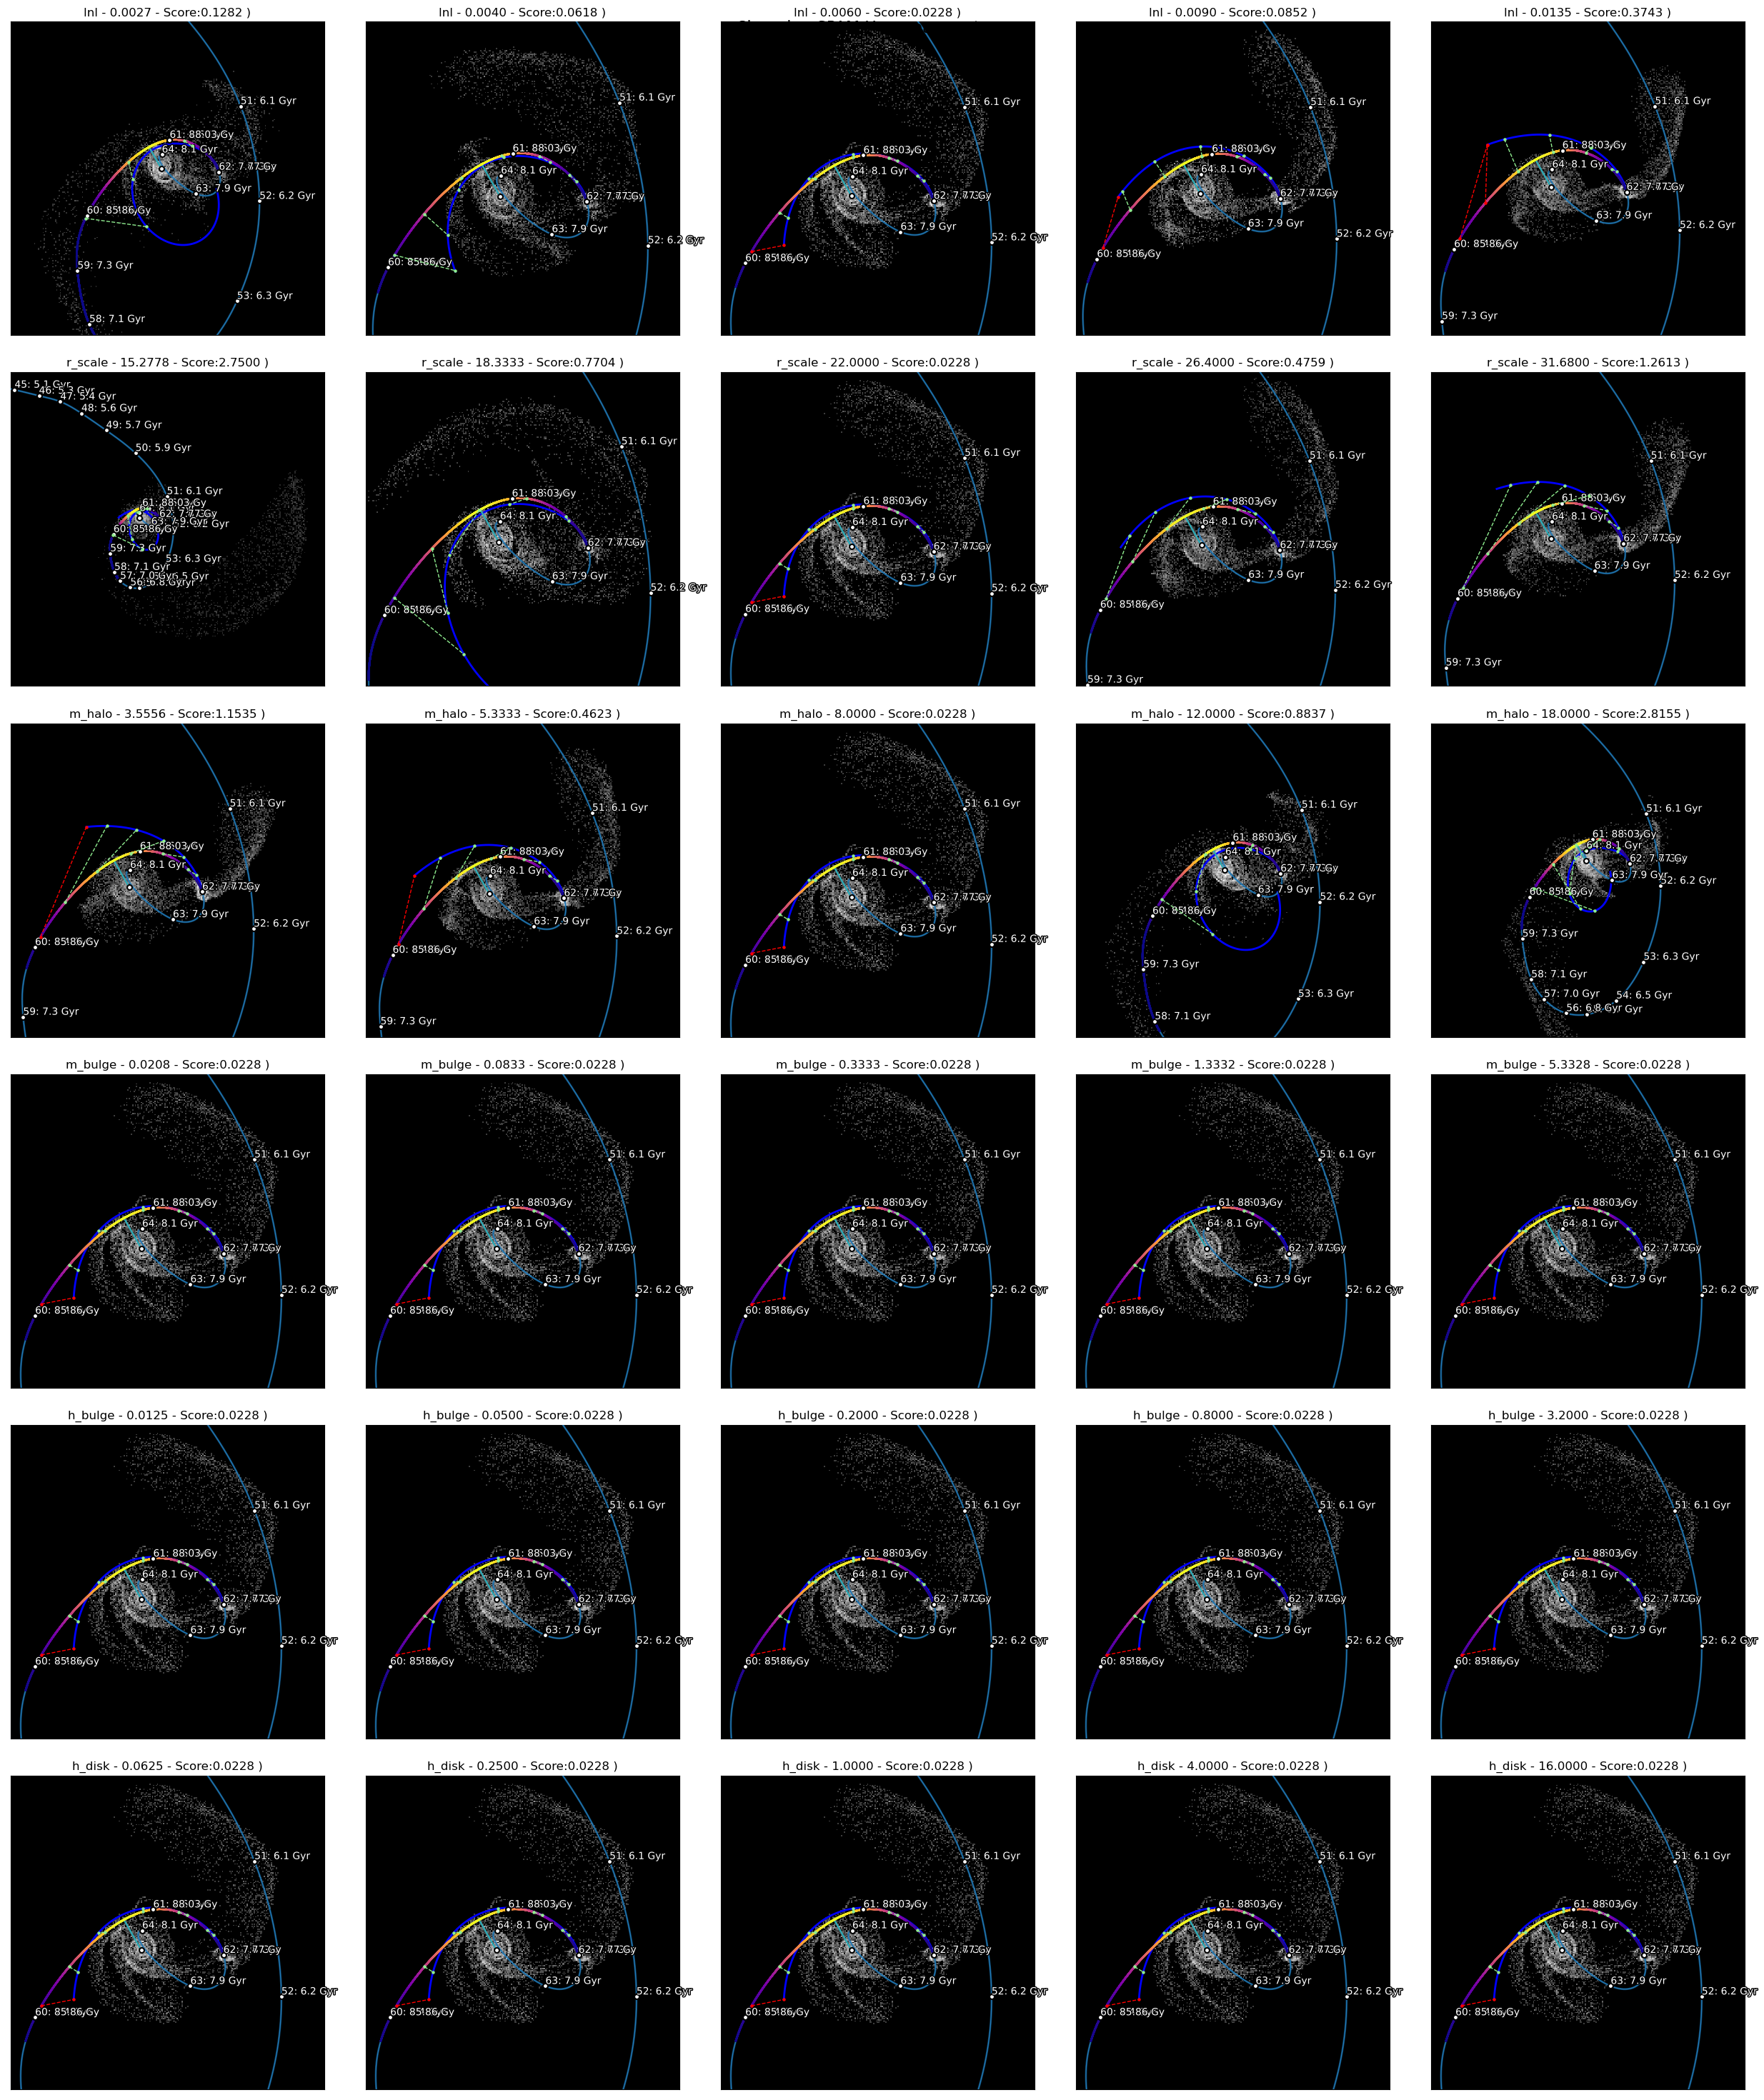

____
# Test GA Tuner

Let's do some small default values to see if it works.



In [16]:
import Optimization_Methods.optimization_support as opts
import Optimization_Methods.optimization_manager as optm

def gen_param_dict( self, param_ar ):
    param_dict = {}
    for i, key in enumerate(self.tuner['parameter_space']):
        param_dict[key['name']] = param_ar[i]
    return param_dict
setattr( SPAM_TNG_Tuner, 'gen_param_dict', gen_param_dict )

def tuner_score_wrapper( self, param_ar ):
    # param ar shoulb be an array of hyper parameters
    self.logger.info("Experiment: Scoring SPAM hyper parameters")
    self.logger.debug("Starting Hyper Parameters: %s", str(type(param_ar)))

    # Convert to dictionary
    param_dict = self.gen_param_dict( param_ar )
    self.logger.debug("Parameter Dictionary: %s", str(param_dict))
    self.logger.debug("Hyper Parameters: %s", str(type(param_dict)))    

    # Get scores for the SPAM orbit
    score_by_time, score_by_pos = self.gen_spam_hyper_param_score(
        param_dict,
        spam_ar = self.spam_ar,
        weight_func = self.tuner['moca_weight_func'],
    )

    # Combine scores
    exp_score = ( self.tuner['time_weight'] * score_by_time ) + ( self.tuner['pos_weight'] * score_by_pos )
    self.logger.debug("Score: %f", exp_score)
    return exp_score
setattr( SPAM_TNG_Tuner, 'tuner_score_wrapper', tuner_score_wrapper )

def setup_spam_tuner( self, tuner_param = None, ga_param = None,
                     name = 'Test Tuner', param_space = None,  ):
    """
    Setup the SPAM Tuner for the given score wrapper
    """

    self.logger.info("Setting up SPAM Tuner")

    # Create container for current tuner
    self.tuner = {}
    self.tuner['name'] = name
    self.tuner['tuner_param'] = tuner_param
    self.logger.info("Tuner Name: %s", self.tuner['name'])

    # Setup Tuner scoring parameters
    self.tuner['time_weight'] = self.tuner['tuner_param']['time_weight']
    self.tuner['pos_weight'] = self.tuner['tuner_param']['pos_weight']
    self.tuner['moca_weight_func'] = self.gen_moca_weight_func( 
        scale_past = self.tuner['tuner_param'].get('moca_scale_past',1.0),
        boundary_value = self.tuner['tuner_param'].get('moca_boundary',0.1),
    )

    #     def gen_moca_weight_func( self, boundary_value = 0.01, scale_past = 1.0 ):

    # Set the SPAM Tuner
    if param_space is None:
        self.tuner['parameter_space'] = [
            {'name':'lnl', 'type': 'float', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform', 'transform':'normalize', },
            {'name':'m_halo', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
            {'name':'r_scale', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
        ]
    else:
        self.tuner['parameter_space'] = param_space

    self.logger.debug("Parameter Space: %s", str(self.tuner['parameter_space']))

    # Create space manager
    self.tuner['space_manager'] = opts.Space_Manager( self.tuner['parameter_space'], log_level=logging.WARNING )
    self.logger.debug("Space Manager: %s", str(type(self.tuner['space_manager'])))
    
    # Create execution manager
    self.tuner['exec_manager'] = opts.Execution_Manager( 
        self.tuner['space_manager'], 
        self.tuner_score_wrapper, 
        normalize_output='reciprocal',
        exec_log_level=logging.WARNING,
    )
    self.logger.debug("Execution Manager: %s", str(type(self.tuner['exec_manager'])))


    self.tuner['ga_manager'] = optm.PYGAD_Manager( ga_param, 
                                    space_manager = self.tuner['space_manager'], 
                                    execution_manager = self.tuner['exec_manager'],
                                    black_box_function=self.tuner_score_wrapper,
                                    log_level=logging.INFO 
                                    )
    self.logger.debug("GA Manager: %s", str(type(self.tuner['ga_manager'])))
    self.logger.info("SPAM Tuner Setup Complete")
setattr( SPAM_TNG_Tuner, 'setup_spam_tuner', setup_spam_tuner )


if buildEnv:

    reload(opts)
    reload(optm)
        
    # Space Hyperparameters
    spam_hyperspace = [
        {'name':'lnl', 'type': 'float', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform', 'transform':'normalize', },
        {'name':'m_halo', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
        {'name':'r_scale', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
    ]

    ga_param = {
        "num_generations": 2,      # Number of generations to run the GA.
        "num_parents_mating": 8,  # Number of solutions to be selected as parents.
        "sol_per_pop": 32,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "random_seed": 0,       # Set random seed for reproducibility.
        "keep_parents": 2,         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
    }

    score_wrapper_param = { 'pos_weight':0.5, 'time_weight':0.5, 'moca_scale_past':0.5, 'moca_boundary':0.1, }

    test_target = SPAM_TNG_Tuner( p1, log_level= logging.WARNING )

    test_target.setup_spam_tuner( 
        tuner_param=score_wrapper_param, 
        name = 'Testing Tuner Exp 0',
        param_space = spam_hyperspace,
        ga_param = ga_param, 
        )


    # Space manager
    n = 3

    r_samples = test_target.tuner['space_manager'].get_random_sample( n )
    print( "\nRANDOM SAMPLES:")
    print( r_samples )

    r_results = test_target.tuner['exec_manager'].evaluate_function( r_samples )
    print( "\nRESULTS:")
    print( r_results )

    print("\nBeginning GA Test Run:")
    test_target.tuner['ga_manager'].gad.run()

    print("Done")
    


[2026-01-09 13:17:05,702 - INFO - optimization_manager.optimizer.<module>]: Imported Loaded
[2026-01-09 13:17:05,702 - INFO - optimization_manager.<module>]: Imported Loaded


[2026-01-09 13:17:06,903 - INFO - parallel_queue_manager._set_local_mode]: Local Manager initialized with 32 workers using local multiprocessing (futures).
[2026-01-09 13:17:06,905 - INFO - optimization_manager.__init__]: Initializing PYGAD Manager
[2026-01-09 13:17:06,906 - INFO - optimization_manager.__init__]: Space Input: 3
[2026-01-09 13:17:06,907 - INFO - optimization_manager.__init__]: Creating Initial Population
[2026-01-09 13:17:06,914 - INFO - optimization_manager.__init__]: Optimization Manager Initialized



RANDOM SAMPLES:
[[0.5488135  0.54488318 0.43758721]
 [0.71518937 0.4236548  0.891773  ]
 [0.60276338 0.64589411 0.96366276]]


[2026-01-09 13:17:08,043 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [=============       ] 2/3
[2026-01-09 13:17:08,279 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 3/3 - Queue Complete



RESULTS:
[[0.26104916]
 [0.94886056]
 [0.71874721]]

Beginning GA Test Run:


[2026-01-09 13:17:09,292 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [================    ] 26/32
[2026-01-09 13:17:09,617 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 32/32 - Queue Complete
[2026-01-09 13:17:10,635 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 31/31 - Queue Complete
[2026-01-09 13:17:11,469 - INFO - parallel_queue_manager._run_local_processes]: Local Manager: Progress: [====================] 30/30 - Queue Complete


Done


In [ ]:
if buildEnv and False:
    
    # Space Hyperparameters
    spam_hyperspace = [
        {'name':'lnl', 'type': 'float', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform', 'transform':'normalize', },
        {'name':'m_halo', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
        {'name':'r_scale', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
    ]

    ga_param = {
        "num_generations": 3,      # Number of generations to run the GA.
        "num_parents_mating": 16,  # Number of solutions to be selected as parents.
        "sol_per_pop": 128,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "random_seed": 0,       # Set random seed for reproducibility.
        "keep_parents": 8,         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.5,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
    }

    test_target = SPAM_TNG_Tuner( p1, log_level= logging.WARNING )
    test_target.gen_moca_weight_func(  )
    test_target.set_log_level( logging.WARNING )
    test_target.prep_exp_1(  )
    test_target.setup_spam_tuner( test_target.exp_1_score_wrapper, 
                                  param_space = spam_hyperspace,
                                  ga_param = ga_param,)


    print("\nBeginning GA Test Run:")
    test_target.tuner['ga_manager'].gad.run()
    x, y = test_target.tuner['exec_manager'].get_results( space='original',)
    test_target.set_log_level( logging.INFO )
    print( f"Results: {x.shape} - {y.shape}" )

    # Get location of lowest point
    min_i = np.argmin( y )
    min_x = x[min_i]
    min_y = y[min_i]

    print( f"Min: {min_x} - {min_y}" )

    best_param = test_target.gen_param_dict( min_x )
    print( f"Best Param: {best_param}" )

    best_orbit = test_target.run_spam_orbit( best_param, test_target.spam_ar )
    best_orbit_anno = test_target.gen_spam_orbit_annotations( best_orbit, )
    print( f"Best Orbit: {best_orbit.shape}" )

    _, best_tidal = test_target.run_spam_particles( best_param, test_target.spam_ar, n_pts= 2000, n_pts_2=10000 )
    print( f"Best Tidal: {best_tidal.shape}" )

    fig, ax = plt.subplots(1, 2, figsize=(20, 12))

    test_target.plot_target( 
        append_plots = ( best_orbit, "Best GA Orbit" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[0],
        
    )

    test_target.plot_target(
        overwrite_hist = best_tidal,
        append_plots = ( best_orbit, "Best GA Tidal" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[1],
        bins = 128
    )
    

In [ ]:
ga_param_sets = {}

base_pop = 320
base_gen = 20 
base_parents_select = base_pop // 8
base_parents_keep = base_pop // 32
base_mut_prob = 0.35
base_mut_rate = 0.1

# Let's setup experiment 1 for bulk target optimization
exp1 = {}

# Setup spam parameter space
exp1['spam_input_space'] = [
    {'name':'lnl', 'type': 'float', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform', 'transform':'normalize', },
    {'name':'m_halo', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
    {'name':'r_scale', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
]

# Setup possible score wrapper parameters
exp1['score_config'] = {}

exp1['score_config']['time_base'] = { 'pos_weight':0.0, 'time_weight':1.0, 'moca_scale_past':1.0, }
exp1['score_config']['time_skew'] = { 'pos_weight':0.0, 'time_weight':1.0, 'moca_scale_past':0.5, }

exp1['score_config']['pos_base'] = { 'pos_weight':1.0, 'time_weight':0.0, 'moca_scale_past':1.0, }
exp1['score_config']['pos_skew'] = { 'pos_weight':1.0, 'time_weight':0.0, 'moca_scale_past':0.5, }

exp1['score_config']['balance_base'] = { 'pos_weight':0.5, 'time_weight':0.5, 'moca_scale_past':1.0, }
exp1['score_config']['balance_skew'] = { 'pos_weight':0.5, 'time_weight':0.5, 'moca_scale_past':0.5, }

# Setup possible ga configurations
exp1['ga_config'] = {}

exp1['ga_config']['test'] = {
        "num_generations": 1,      # Number of generations to run the GA.
        "num_parents_mating": 16,  # Number of solutions to be selected as parents.
        "sol_per_pop": 30,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "random_seed": 0,       # Set random seed for reproducibility.
        "keep_parents": 4,         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.33,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
    }

exp1['ga_config']['balance'] = {
        "num_generations": base_gen,   # Number of generations to run the GA.
        "sol_per_pop": base_pop,        # Number of solutions per population.

        "num_parents_mating": base_parents_select,  # Number of solutions to be selected as parents.
        "keep_parents": base_parents_keep,          # Number of top solutions to keep in the next generation. (chance of mutation)

        "mutation_probability": base_mut_prob,      # Probability of mutating a gene.
        "random_mutation_min_val": -base_mut_rate,  # Minimum value for random mutation.
        "random_mutation_max_val":  base_mut_rate,  # Maximum value for random mutation.
        
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        # "random_seed": 0,       # Set random seed for reproducibility.
    }

exp1['ga_config']['explore'] = {
        "num_generations": base_gen//2,   # Number of generations to run the GA.
        "sol_per_pop": base_pop*2,        # Number of solutions per population.

        "num_parents_mating": base_parents_select,  # Number of solutions to be selected as parents.
        "keep_parents": base_parents_keep//2,          # Number of top solutions to keep in the next generation. (chance of mutation)

        "mutation_probability": base_mut_prob*2,      # Probability of mutating a gene.
        "random_mutation_min_val": -base_mut_rate*2,  # Minimum value for random mutation.
        "random_mutation_max_val":  base_mut_rate*2,  # Maximum value for random mutation.
        
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        # "random_seed": 0,       # Set random seed for reproducibility.
    }

exp1['ga_config']['exploit'] = {
        "num_generations": base_gen*2,   # Number of generations to run the GA.
        "sol_per_pop": base_pop//2,        # Number of solutions per population.

        "num_parents_mating": base_parents_select,  # Number of solutions to be selected as parents.
        "keep_parents": base_parents_keep*2,          # Number of top solutions to keep in the next generation. (chance of mutation)

        "mutation_probability": base_mut_prob/2,      # Probability of mutating a gene.
        "random_mutation_min_val": -base_mut_rate/2,  # Minimum value for random mutation.
        "random_mutation_max_val":  base_mut_rate/2,  # Maximum value for random mutation.
        
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        # "random_seed": 0,       # Set random seed for reproducibility.
    }

def func_experiment_1( cmdline_args ):
    """
    Wrapper function for the experiment
    """

    logger.info( f"Running Experiment 1" )
    logger.debug( f"Command Line Args: {cmdline_args}" )

    # Assert that the command line args are valid
    assert cmdline_args.target_id is not None, "Target ID must be provided"
    assert cmdline_args.input is not None, "Input setting must be provided"
    assert cmdline_args.input2 is not None, "Input2 setting must be provided"
    assert cmdline_args.output is not None, "Output setting must be provided"

    # Assert the corresponding settings are valid
    assert cmdline_args.input in exp1['score_config'], f"Input setting {cmdline_args.input} is not valid"
    assert cmdline_args.input2 in exp1['ga_config'], f"Input2 setting {cmdline_args.input2} is not valid"
    assert os.path.exists( cmdline_args.output ), f"Output setting {cmdline_args.output} is not valid"

    # Define final save locations

    name = f"cmp-tng-spam-exp_target={cmdline_args.target_id}_score={cmdline_args.input}_ga={cmdline_args.input2}"

    results_loc = os.path.join( 
        cmdline_args.output, 
        f"{name}_results.csv" 
        )
    image_loc = os.path.join(
        cmdline_args.output, 
        f"{name}_results.png" 
        )
    
    # Check if the csv and png files already exist
    if os.path.exists( results_loc ) and os.path.exists( image_loc ) and cmdline_args.overwrite is False:
        logger.warning( f"Results image file already exists. Exiting.\n{results_loc}" )
        return

    # Setup target
    try:
        tng_target = SPAM_TNG_Tuner( cmdline_args.target_id, log_level= logging.WARNING )
    except Exception as e:
        logger.error( f"Error setting up target: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("Target Setup Complete")
    

    # Setup the SPAM Tuner Experiment
    try:
        tng_target.setup_spam_tuner( 
            tuner_param=exp1['score_config'][cmdline_args.input],
            ga_param=exp1['ga_config'][cmdline_args.input2], 
            name = name,
            param_space = exp1['spam_input_space'],
            )
    except Exception as e:
        logger.error( f"Error setting up SPAM Tuner: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("SPAM Tuner Setup Complete")

    # Run Experiment
    try:
        tng_target.tuner['ga_manager'].gad.run()
    except Exception as e:
        logger.error( f"Error running GA: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("GA Run Complete")

    
    # Get Results
    x, y = tng_target.tuner['exec_manager'].get_results( space='original',)
    logger.info( f"Results: {x.shape} - {y.shape}" )

    # combine results 
    df = pd.DataFrame( x, columns = [ k['name'] for k in tng_target.tuner['parameter_space'] ] )
    df['error'] = y
    df.to_csv( results_loc, index=False )
    logger.info( f"Results saved to {results_loc}" )

    # Get minimum y
    min_i = np.argmin( y )
    logger.info( f"Minimum Index: {min_i}" )

    min_x = x[min_i]
    logger.info( f"Minimum X: {min_x}" )

    min_y = y[min_i]
    logger.info( f"Minimum Y: {min_y}" )

    # Visualize the best result
    logger.info(f"Best Param ar: {min_x} - {min_y}")
    best_param = tng_target.gen_param_dict( min_x )
    logger.info(f"Best Param: {best_param}")

    best_orbit = tng_target.run_spam_orbit( spam_param = best_param )
    logger.info( f"Best Orbit: {best_orbit.shape}" )

    best_orbit_anno = tng_target.gen_spam_orbit_annotations( best_orbit, )

    _, best_tidal = tng_target.run_spam_particles( spam_param = best_param, n_pts= 1000, n_pts_2=1000 )
    logger.info( f"Best Tidal: {best_tidal.shape}" )

    fig, ax = plt.subplots(1, 2, figsize=(20, 12))

    # Primary title
    fig.suptitle(f"SPAM Tuner - {name}", fontsize=16)
    fig.tight_layout()

    tng_target.plot_target( 
        append_plots = ( best_orbit, "Best GA Orbit" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[0],  
        bins = 256,      
        plot_title = 'TNG Target Tidal Features'
    )

    tng_target.plot_target(
        overwrite_hist = best_tidal,
        append_plots = ( best_orbit, "Best GA Orbit" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[1],
        bins = 128,
        plot_title = "Best SPAM Tidal Features"
    )

    # Save figure
    fig.savefig( image_loc, dpi=300 )
    logger.info( f"Results saved to {image_loc}" )


if buildEnv and True:

    cmdLine = "python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py"
    cmdLine += " --function exp_1"
    cmdLine += " --target_id 62000000190717"

    cmdLine += ' --input balance_base'
    cmdLine += ' --input2 test'
    cmdLine += " --output /home/mbo2d/galStuff/data/spam_tuner_exp_1"

    print("Running Example Command Line:")
    print( cmdLine )
    print("Example MPI Example Command Line:")
    # print( f"mpirun -n 32 {cmdLine}" )
    print( f"mpiexec --bind-to none --oversubscribe -n 32 {cmdLine}" )

    # Add mpiexec to the front of the command

    # cmd_parser = gu.ArgHandler()
    # test_cmd_lines = cmd_parser.parse_args_from_string(cmdLine)

if script_args.function == 'exp_1':
    # Run the func_experiment_1_wrapper
    func_experiment_1( script_args )

Running Example Command Line:
python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py --function exp_1 --target_id 62000000190717 --input balance_base --input2 test --output /home/mbo2d/galStuff/data/spam_tuner_exp_1
Example MPI Example Command Line:
mpiexec --bind-to none --oversubscribe -n 32 python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py --function exp_1 --target_id 62000000190717 --input balance_base --input2 test --output /home/mbo2d/galStuff/data/spam_tuner_exp_1


In [ ]:

if buildEnv and False:

    cmdLine = "python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py"
    cmdLine += " --function exp_1"
    cmdLine += " --target_id 62000000190717"

    cmdLine += ' --input balance_base'
    cmdLine += ' --input2 test'
    cmdLine += " --output /home/mbo2d/galStuff/data/spam_tuner"

    print("Running Example Command Line:")
    print( cmdLine )
    print("Example MPI Example Command Line:")
    print( f"mpirun -n 32 {cmdLine}" )

    # Add mpiexec to the front of the command

    cmd_parser = gu.ArgHandler()
    test_cmd_lines = cmd_parser.parse_args_from_string(cmdLine)

    # Tested, confirmed to pass
    # func_experiment_1( test_cmd_lines )

    # Create base cmd line args
    base_cmd_line = "python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py"
    base_cmd_line += " --function exp_1"
    # base_cmd_line += " --target_id 62000000190717"
    base_cmd_line += " --output /home/mbo2d/galStuff/data/spam_tuner"

    # ALL TARGET TEST 
    target_list = os.listdir('/home/mbo2d/galStuff/data/tng-data/')
    target_list = [ int(x.split('_')[1].split('.')[0]) for x in target_list if 'pts' in x ]
    target_list.sort()

    print( f"Target List: {target_list}")
    for tid in target_list:
    #     try:
    #         t = TNG_Target_Class( pid, load_particles = True, log_level=logging.WARNING )
    #         print( f"Loaded Target: {pid} - {t.current_state['snap']} - {t.pts.shape}")
    #     except Exception as e:
    #         print( f"Failed to load target: {pid} - {e}")
    #         continue
    # loop through all combinations of input and input2
    # for tid in [ p1, p2 ]:
        for input_key in exp1['score_config']:
            for input2_key in exp1['ga_config']:

                # Skip test ga_config
                if input2_key == 'test':
                    continue

                # Create command line
                cmdLine = base_cmd_line
                cmdLine += f" --target_id {tid}"
                cmdLine += f" --input {input_key}"
                cmdLine += f" --input2 {input2_key}"

                # Print command line
                print("Running Command Line:")
                print( cmdLine )
                print("MPI Example Command Line:")
                print( f"mpiexec --bind-to none --oversubscribe -n 32 {cmdLine}" )

                # Parse command line
                test_args = cmd_parser.parse_args_from_string(cmdLine)

                # Run the experiment
                # func_experiment_1( test_args )
                

## Reviewing Experiment 1 Results



In [ ]:
if buildEnv and False:
    result  s_dir = '/home/mbo2d/galStuff/data/spam_tuner_exp_1'
    if not os.path.exists( results_dir ):
        raise FileNotFoundError( f"Results directory {results_dir} does not exist" )

    # Get all files in the directory
    files = os.listdir( results_dir )

    results_list = []

    # Loop through files
    for f in files:

        # only process csv files
        if f.endswith( '.csv' ):

            # Remove the .csv extension and split the file name for important info
            parts = f[:-4].split('__')
            # print( f"{f} - {parts}" )
            
            r_dict = {
                'target_id': int(parts[0].split('=')[1]),
                'score': parts[1].split('=')[1],
                'ga_config': parts[2].split('=')[1].split('_')[0],
                'results_loc': os.path.join( results_dir, f ),
                'results_name': f,
                'best_image': f.replace( '.csv', '.png' ),
            }

            # print( f"Results Dict: {r_dict}" )
            results_list.append( r_dict )

    r_df = pd.DataFrame( results_list )

    r_df['target_id'] = r_df['target_id'].astype(int)
    print( r_df )

    # Pick one 
    r = r_df[ r_df['target_id'] == p1][r_df['score'] == 'time_base']

    xy_df = None

    for i, row in r.iterrows():

        # Read the csv file
        df = pd.read_csv( row['results_loc'] )
        print( f"DataFrame: {df.shape}" )

        if xy_df is None:
            xy_df = df
        else:
            xy_df = pd.concat( [xy_df, df], axis=0 )


In [ ]:
import seaborn as sns
def plot_experiment_1_results( df, x, y, z='error', agg='min', bins=20, ext_ax=None ):
    """
    Plot the experiment results
    """

    if ext_ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    else:
        ax = ext_ax

    epsilon = 1e-8
    df['log_error'] = np.log10(df['error'] + epsilon)

    # Helper to create bins and label them with bin centers
    def bin_with_centers(series, is_log=False):
        data = np.log10(series) if is_log else series
        bin_edges = np.linspace(data.min(), data.max(), bins + 1)
        bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
        labels = bin_centers.round(1)  # round for clean axis labels
        binned = pd.cut(data, bins=bin_edges, labels=labels, include_lowest=True)
        return binned

    df['x_bin'] = bin_with_centers(df[x], is_log=(x == 'lnl'))
    df['y_bin'] = bin_with_centers(df[y], is_log=(y == 'lnl'))

    pivot = df.pivot_table(index='x_bin', columns='y_bin', values='log_error', aggfunc=agg)
    sns.heatmap(pivot, ax=ax, cmap='viridis_r', cbar_kws={'label': 'Log(Error)'})

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"Heatmap of {agg} Error by {x} and {y}")

    ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)



if buildEnv and False:
    # Create 4 plots
    fig, ax = plt.subplots(1,4, figsize=(36, 12))
    fig.suptitle("Experiment 1 Results", fontsize=16)

    # img = plt.imread( r['best_image'].iloc[0] )
    plot_experiment_1_results( xy_df, 'm_halo', 'r_scale', agg='min', ext_ax=ax[0,1] )
    plot_experiment_1_results( xy_df, 'lnl', 'r_scale', agg='min', ext_ax=ax[1,0] )
    plot_experiment_1_results( xy_df, 'lnl', 'm_halo', agg='min', ext_ax=ax[1,1] )
    

In [ ]:
if buildEnv and False:
     #loop over targets found in the directory
     target_list = r_df['target_id'].unique()

     # Create 4 subplots

     for tid in target_list:
          t_df = r_df[ r_df['target_id'] == tid ]
          t_df = t_df[ r_df['score'] == 'time_base' ]
          # print( f"Target ID: {tid} - {t_df.shape}" )

          # Create 4 subplots
          fig, ax = plt.subplots(1, 4, figsize=(36, 6))

          # Collect all csv files into a single dataframe
          xy_df = None
          for i, row in t_df.iterrows():
               # Read the csv file
               df = pd.read_csv( row['results_loc'] )

               if xy_df is None:
                    xy_df = df
               else:
                    xy_df = pd.concat( [xy_df, df], axis=0 )

          # print( f"Combined DataFrame: {xy_df.shape}" )
          
          # Read image for the balanced balanced
          img_loc = os.path.join( results_dir, t_df[t_df['ga_config']=='balance']['best_image'].values[0] )
          # print( f"Image Location: {img_loc}" )

          # Read image and place in first subplot
          img = plt.imread( img_loc )
          ax[0].imshow( img )

          
          plot_experiment_1_results( xy_df, 'lnl', 'm_halo', agg='min', ext_ax=ax[1] )
          plot_experiment_1_results( xy_df, 'lnl', 'r_scale', agg='min', ext_ax=ax[2] )
          plot_experiment_1_results( xy_df, 'm_halo', 'r_scale', agg='min', ext_ax=ax[3] )

          plt.show()


          # Create 

In [ ]:
if buildEnv and False:
    x, y = test_target.tuner['exec_manager'].get_results( space='original',)
    test_target.set_log_level( logging.INFO )
    print( f"Results: {x.shape} - {y.shape}" )

    # Get location of lowest point
    min_i = np.argmin( y )
    min_x = x[min_i]
    min_y = y[min_i]

    print( f"Min: {min_x} - {min_y}" )

    best_param = test_target.gen_param_dict( min_x )
    print( f"Best Param: {best_param}" )

    best_orbit = test_target.run_spam_orbit( best_param, test_target.spam_ar )
    best_orbit_anno = test_target.gen_spam_orbit_annotations( best_orbit, )
    print( f"Best Orbit: {best_orbit.shape}" )

    _, best_tidal = test_target.run_spam_particles( best_param, test_target.spam_ar, n_pts= 2000, n_pts_2=10000 )
    print( f"Best Tidal: {best_tidal.shape}" )

    fig, ax = plt.subplots(1, 2, figsize=(20, 12))

    test_target.plot_target( 
        append_plots = ( best_orbit, "Best GA Orbit" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[0],
        
    )

    test_target.plot_target(
        overwrite_hist = best_tidal,
        append_plots = ( best_orbit, "Best GA Tidal" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[1],
        bins = 128
    )

---
---
## Previous Gridsearch results

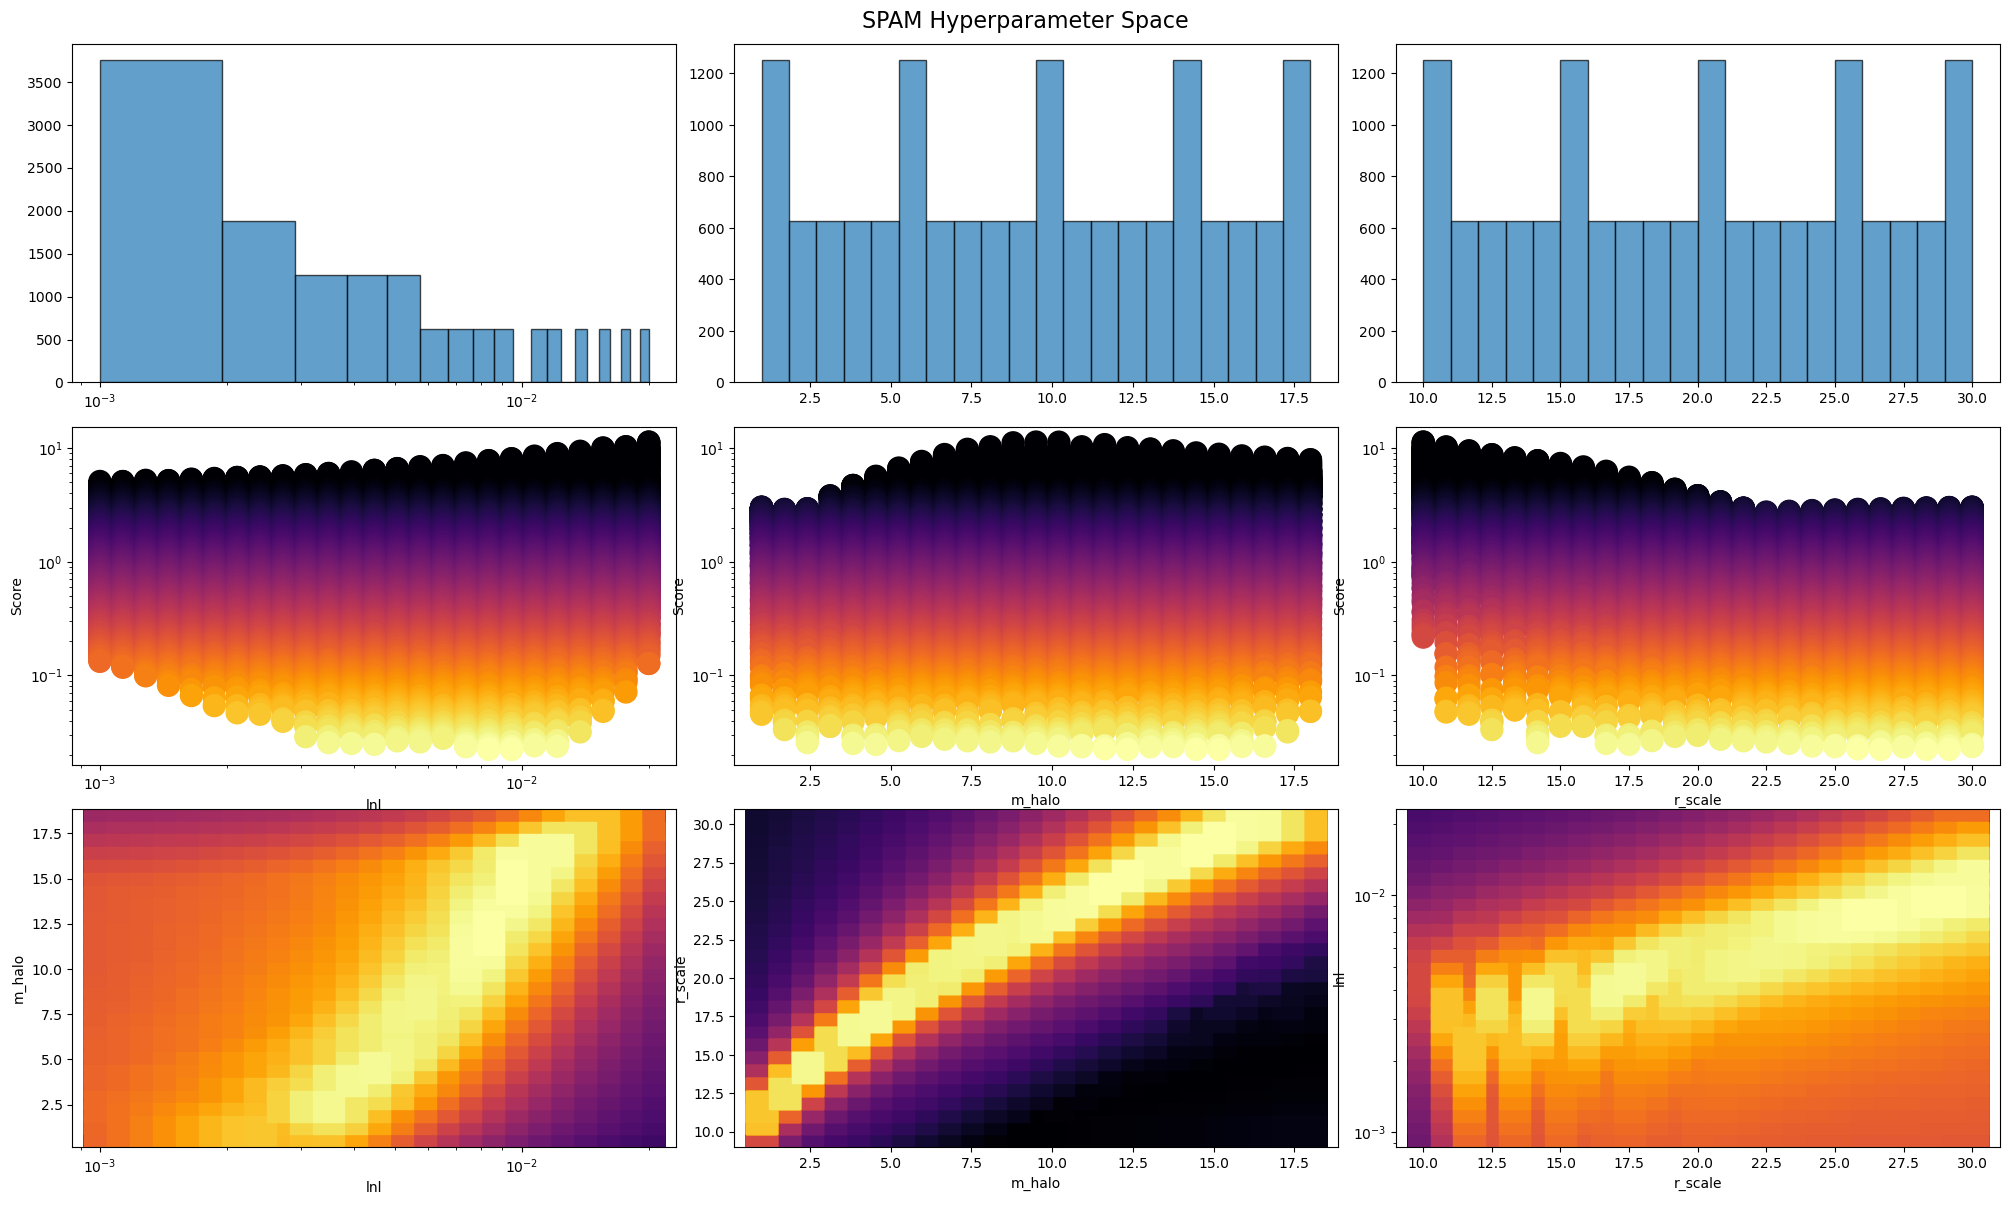

# Experiment 2: GA Tuner Results

Exp 1 went well.  Let's take the best results from each target, and see how well the GA tuner does.

In [ ]:
ga_param_sets = {}

base_pop = 320
base_gen = 20 
base_parents_select = base_pop // 8
base_parents_keep = base_pop // 32
base_mut_prob = 0.35
base_mut_rate = 0.1

# Let's setup experiment 1 for bulk target optimization
exp2 = {}

# Setup spam parameter space
exp2['spam_input_space'] = [
    {'name':'lnl', 'type': 'float', 'bounds': [1e-4, 1e-1], 'prior':'log-uniform', 'transform':'normalize', },
    {'name':'m_halo', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
    {'name':'r_scale', 'type': 'float', 'bounds': [2, 30], 'prior':'uniform', 'transform':'normalize', },
]

# Setup possible score wrapper parameters
exp2['score_config'] = {}
exp2['score_config']['time_base'] = { 'pos_weight':0.0, 'time_weight':1.0, 'moca_scale_past':1.0, }

# Setup possible ga configurations
exp2['ga_config'] = {}

exp2['ga_config']['test'] = {
        "num_generations": 1,      # Number of generations to run the GA.
        "num_parents_mating": 16,  # Number of solutions to be selected as parents.
        "sol_per_pop": 30,        # Number of solutions per population.
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        "random_seed": 0,       # Set random seed for reproducibility.
        "keep_parents": 4,         # Number of top solutions to keep in the next generation.
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "mutation_probability": 0.33,      # Probability of mutating a gene.
        "random_mutation_min_val": -0.1,  # Minimum value for random mutation.
        "random_mutation_max_val":  0.1,  # Maximum value for random mutation.
    }

exp2['ga_config']['exploit'] = {
        "num_generations": base_gen*2,   # Number of generations to run the GA.
        "sol_per_pop": base_pop//2,        # Number of solutions per population.

        "num_parents_mating": base_parents_select,  # Number of solutions to be selected as parents.
        "keep_parents": base_parents_keep*2,          # Number of top solutions to keep in the next generation. (chance of mutation)

        "mutation_probability": base_mut_prob/2,      # Probability of mutating a gene.
        "random_mutation_min_val": -base_mut_rate/2,  # Minimum value for random mutation.
        "random_mutation_max_val":  base_mut_rate/2,  # Maximum value for random mutation.
        
        "parent_selection_type": "sus",   # Parent selection strategy 
        "crossover_type": "uniform", # Crossover strategy.        
        "gene_type": float,        # Data type of the genes. Can be float, int, or a list of types.
        # "random_seed": 0,       # Set random seed for reproducibility.
    }

def func_experiment_2( cmdline_args ):
    """
    Wrapper function for the experiment
    """

    logger.info( f"Running Experiment 2" )
    logger.debug( f"Command Line Args: {cmdline_args}" )

    # Assert that the command line args are valid
    assert cmdline_args.target_id is not None, "Target ID must be provided"
    assert cmdline_args.input is not None, "Input setting must be provided"
    assert cmdline_args.input2 is not None, "Input2 setting must be provided"
    assert cmdline_args.output is not None, "Output setting must be provided"

    # Assert the corresponding settings are valid
    assert cmdline_args.input in exp2['score_config'], f"Input setting {cmdline_args.input} is not valid"
    assert cmdline_args.input2 in exp2['ga_config'], f"Input2 setting {cmdline_args.input2} is not valid"
    assert os.path.exists( cmdline_args.output ), f"Output setting {cmdline_args.output} is not valid"

    # Define final save locations

    name = f"cmp-tng-spam-exp_target={cmdline_args.target_id}_score={cmdline_args.input}_ga={cmdline_args.input2}"

    results_loc = os.path.join( 
        cmdline_args.output, 
        f"{name}_results.csv" 
        )
    image_loc = os.path.join(
        cmdline_args.output, 
        f"{name}_results.png" 
        )
    
    # Check if the csv and png files already exist
    if os.path.exists( results_loc ) and os.path.exists( image_loc ) and cmdline_args.overwrite is False:
        logger.warning( f"Results image file already exists. Exiting.\n{results_loc}" )
        return

    # Setup target
    try:
        tng_target = SPAM_TNG_Tuner( cmdline_args.target_id, log_level= logging.WARNING )
    except Exception as e:
        logger.error( f"Error setting up target: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("Target Setup Complete")
    

    # Setup the SPAM Tuner Experiment
    try:
        tng_target.setup_spam_tuner( 
            tuner_param=exp2['score_config'][cmdline_args.input],
            ga_param=exp2['ga_config'][cmdline_args.input2], 
            name = name,
            param_space = exp2['spam_input_space'],
            )
    except Exception as e:
        logger.error( f"Error setting up SPAM Tuner: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("SPAM Tuner Setup Complete")

    # Run Experiment
    try:
        tng_target.tuner['ga_manager'].gad.run()
    except Exception as e:
        logger.error( f"Error running GA: {e}" )
        print( f"Error: {e}" )
        return
    logger.info("GA Run Complete")

    
    # Get Results
    x, y = tng_target.tuner['exec_manager'].get_results( space='original',)
    logger.info( f"Results: {x.shape} - {y.shape}" )

    # combine results 
    df = pd.DataFrame( x, columns = [ k['name'] for k in tng_target.tuner['parameter_space'] ] )
    df['error'] = y
    df.to_csv( results_loc, index=False )
    logger.info( f"Results saved to {results_loc}" )

    # Get minimum y
    min_i = np.argmin( y )
    logger.info( f"Minimum Index: {min_i}" )

    min_x = x[min_i]
    logger.info( f"Minimum X: {min_x}" )

    min_y = y[min_i]
    logger.info( f"Minimum Y: {min_y}" )

    # Visualize the best result
    logger.info(f"Best Param ar: {min_x} - {min_y}")
    best_param = tng_target.gen_param_dict( min_x )
    logger.info(f"Best Param: {best_param}")

    best_orbit = tng_target.run_spam_orbit( spam_param = best_param )
    logger.info( f"Best Orbit: {best_orbit.shape}" )

    best_orbit_anno = tng_target.gen_spam_orbit_annotations( best_orbit, )

    # If testing, reduce n_pts
    if cmdline_args.input2 == 'test':
        n_pts = 1000
    else:
        n_pts = 100000

    _, best_tidal = tng_target.run_spam_particles( spam_param = best_param, n_pts= n_pts )
    logger.info( f"Best Tidal: {best_tidal.shape}" )

    fig, ax = plt.subplots(1, 2, figsize=(20, 12))

    # Primary title
    fig.suptitle(f"SPAM Tuner - {name}", fontsize=16)
    fig.tight_layout()

    tng_target.plot_target( 
        append_annotations = best_orbit_anno,
        ext_ax = ax[0],  
        plot_title = 'TNG Target Tidal Features'
    )

    tng_target.plot_target(
        overwrite_hist = best_tidal,
        append_plots = ( best_orbit, "Best GA Orbit" ),
        append_annotations = best_orbit_anno,
        ext_ax = ax[1],
        plot_title = "Best SPAM Tidal Features"
    )

    # Save figure
    fig.savefig( image_loc, dpi=300 )
    logger.info( f"Results saved to {image_loc}" )


if buildEnv and True:

    cmdLine = "python3 /home/mbo2d/galStuff/galaxyJSPAM/IllustrisTNG/compare_tng_to_spam.py"
    cmdLine += " --function exp_1"
    cmdLine += " --target_id 62000000190717"

    cmdLine += ' --input balance_base'
    cmdLine += ' --input2 test'
    cmdLine += " --output /home/mbo2d/galStuff/data/spam_tuner_exp_1"

    print("Running Example Command Line:")
    print( cmdLine )
    print("Example MPI Example Command Line:")
    # print( f"mpirun -n 32 {cmdLine}" )
    print( f"mpiexec --bind-to none --oversubscribe -n 32 {cmdLine}" )

    # Add mpiexec to the front of the command

    # cmd_parser = gu.ArgHandler()
    # test_cmd_lines = cmd_parser.parse_args_from_string(cmdLine)

if script_args.function == 'exp_1':
    # Run the func_experiment_1_wrapper
    func_experiment_1( script_args )